# GBFS is not optimal because it ignores g(n). A* combines g(n)+h(n) and is complete
# and optimal here because Manhattan is admissible/consistent. Both use a priority queue
# and best-known path cost, so worst-case time and space are exponential, while a useful
# heuristic can greatly reduce the number of expanded states.

# BFS: complete and optimal for finite unit-cost mazes; time O(b^(d+1)), space O(b^d).
# DFS with path cycle checking: not optimal; worst-case time O(b^m) and active space O(bm).
# On a finite graph, complete exploration is possible when all cycles are prevented, but
# open mazes can make the path-only DFS tree extremely large.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file. 


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze. 

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent 
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.** 
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state. 
* **Discrete** means that we have a **finite set of states.** The maze has a finite set 
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The 
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible. 

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [1]:

import os, time, math, heapq
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import maze_helper as mh

MAZE_FILES=["small_maze.txt","medium_maze.txt","large_maze.txt","open_maze.txt",
            "L_maze.txt","loops_maze.txt","empty_maze.txt","empty_maze_2.txt"]
ACTIONS=[("N",(-1,0)),("E",(0,1)),("S",(1,0)),("W",(0,-1))]

def neighbors(maze,pos):
    r,c=pos
    for action,(dr,dc) in ACTIONS:
        q=(r+dr,c+dc)
        if 0<=q[0]<maze.shape[0] and 0<=q[1]<maze.shape[1] and maze[q]!="X":
            yield action,q

class Node:
    def __init__(self,pos,parent=None,action=None,cost=0):
        self.pos=tuple(pos); self.parent=parent; self.action=action; self.cost=cost
    def __str__(self): return f"Node(pos={self.pos}, action={self.action}, cost={self.cost})"
    def get_path_from_root(self):
        out=[]; n=self
        while n is not None: out.append(n); n=n.parent
        return out[::-1]

def _result(node,expanded,depth,frontier,memory,elapsed,status="solved",limit=None,explored=None):
    if node is None:
        return dict(path=None,actions=None,cost=None,expanded=expanded,max_depth=depth,
                    max_frontier=frontier,max_memory=memory,time=elapsed,status=status,limit=limit,explored=set() if explored is None else explored)
    p=node.get_path_from_root()
    return dict(path=[x.pos for x in p],actions=[x.action for x in p[1:]],cost=node.cost,
                expanded=expanded,max_depth=depth,max_frontier=frontier,max_memory=memory,
                time=elapsed,status=status,limit=limit,explored=set() if explored is None else explored)

def bfs(maze,start,goal):
    t=time.perf_counter(); root=Node(start); q=deque([root]); reached={start}
    expanded=depth=0; mf=mm=1; explored=set()
    while q:
        n=q.popleft(); expanded+=1; explored.add(n.pos); depth=max(depth,n.cost)
        if n.pos==goal: return _result(n,expanded,depth,mf,mm,time.perf_counter()-t,explored=explored)
        for a,p in neighbors(maze,n.pos):
            if p not in reached:
                reached.add(p); q.append(Node(p,n,a,n.cost+1))
                mf=max(mf,len(q)); mm=max(mm,len(q)+len(reached))
    return _result(None,expanded,depth,mf,mm,time.perf_counter()-t,"no_solution",explored=explored)

def dfs(maze,start,goal,max_expansions=200_000):
    # DFS has no global reached set; cycle checking is limited to the current path.
    t=time.perf_counter(); root=Node(start); path={start}; stack=[[root,None,0]]
    expanded=depth=mf=0; explored=set()
    while stack:
        n,ch,i=stack[-1]
        if ch is None:
            expanded+=1; explored.add(n.pos); depth=max(depth,n.cost); mf=max(mf,len(stack))
            if expanded>max_expansions:
                return _result(None,expanded,depth,mf,mf,time.perf_counter()-t,
                                "N/A* expansion limit",max_expansions,explored)
            if n.pos==goal: return _result(n,expanded,depth,mf,mf,time.perf_counter()-t,explored=explored)
            ch=[Node(p,n,a,n.cost+1) for a,p in neighbors(maze,n.pos) if p not in path]
            stack[-1][1]=ch
        if i>=len(stack[-1][1]):
            path.remove(n.pos); stack.pop(); continue
        child=stack[-1][1][i]; stack[-1][2]+=1; path.add(child.pos); stack.append([child,None,0])
    return _result(None,expanded,depth,mf,mf,time.perf_counter()-t,"no_solution",explored=explored)

def manhattan(p,g): return abs(p[0]-g[0])+abs(p[1]-g[1])
def euclidean(p,g): return math.hypot(p[0]-g[0],p[1]-g[1])

def best_first(maze,start,goal,strategy="GBFS",heuristic=manhattan,weight=1.0):
    t=time.perf_counter(); root=Node(start); counter=0
    h=heuristic(start,goal); priority=h if strategy=="GBFS" else weight*h
    heap=[(priority,0,counter,root)]; reached={start:0}; expanded=depth=0; mf=mm=1; explored=set()
    while heap:
        _,_,_,n=heapq.heappop(heap)
        if reached.get(n.pos)!=n.cost: continue
        expanded+=1; explored.add(n.pos); depth=max(depth,n.cost)
        if n.pos==goal: return _result(n,expanded,depth,mf,mm,time.perf_counter()-t,explored=explored)
        for a,p in neighbors(maze,n.pos):
            g=n.cost+1
            if p not in reached or g<reached[p]:
                reached[p]=g; counter+=1; h=heuristic(p,goal)
                pri=h if strategy=="GBFS" else g+weight*h
                heapq.heappush(heap,(pri,g,counter,Node(p,n,a,g)))
                mf=max(mf,len(heap)); mm=max(mm,len(heap)+len(reached))
    return _result(None,expanded,depth,mf,mm,time.perf_counter()-t,"no_solution",explored=explored)

def gbfs(maze,start,goal,heuristic=manhattan): return best_first(maze,start,goal,"GBFS",heuristic)
def astar(maze,start,goal,heuristic=manhattan): return best_first(maze,start,goal,"A*",heuristic)

def load_maze(fn):
    with open(fn,encoding="utf-8") as f: maze=mh.parse_maze(f.read())
    return maze,mh.find_pos(maze,"S"),mh.find_pos(maze,"G")

def mark_solution(maze,result):
    shown=np.copy(maze)
    for p in result.get("explored",set()):
        if shown[p] not in ("S","G"): shown[p]="."
    if result.get("path"):
        for p in result["path"]:
            if shown[p] not in ("S","G"): shown[p]="P"
    return shown


In [2]:
import os
print('Working directory:',os.getcwd())

Working directory: /mnt/data/lab02_completed/lab02 - Searching


In [3]:
required=['maze_helper.py']+MAZE_FILES
missing=[f for f in required if not os.path.exists(f)]
if missing: raise FileNotFoundError(missing)
print(f'All {len(required)} required local files are available.')

All 9 required local files are available.


Here is the small example maze:

In [4]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`. 

In [5]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

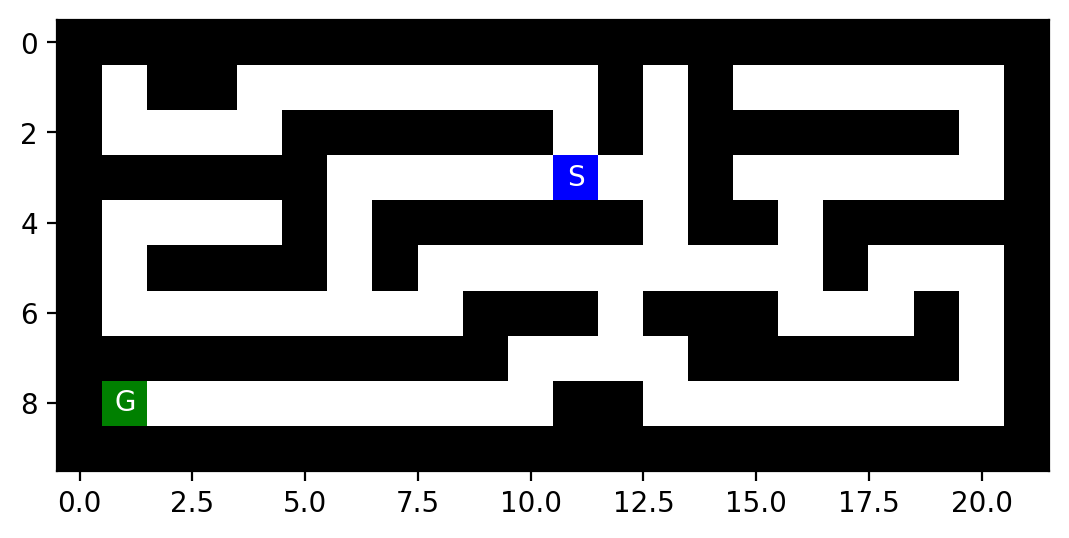

In [6]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [7]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [8]:
# The local helper exposes parse_maze, find_pos, look and visualization utilities.

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step. 

In [9]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0
        
        # check if plan is completed
        if self.progress >= len(self.plan):        
            raise Exception("Completed Plan. No more planned actions")
        
        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [10]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['S', 'W', 'S', 'W', 'W', 'W', 'N', 'E', 'W', 'W']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [11]:
# The random-plan environment is intentionally not executed in the final submission.

Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python. 
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [12]:

import os, time, math, heapq
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import maze_helper as mh

MAZE_FILES=["small_maze.txt","medium_maze.txt","large_maze.txt","open_maze.txt",
            "L_maze.txt","loops_maze.txt","empty_maze.txt","empty_maze_2.txt"]
ACTIONS=[("N",(-1,0)),("E",(0,1)),("S",(1,0)),("W",(0,-1))]

def neighbors(maze,pos):
    r,c=pos
    for action,(dr,dc) in ACTIONS:
        q=(r+dr,c+dc)
        if 0<=q[0]<maze.shape[0] and 0<=q[1]<maze.shape[1] and maze[q]!="X":
            yield action,q

class Node:
    def __init__(self,pos,parent=None,action=None,cost=0):
        self.pos=tuple(pos); self.parent=parent; self.action=action; self.cost=cost
    def __str__(self): return f"Node(pos={self.pos}, action={self.action}, cost={self.cost})"
    def get_path_from_root(self):
        out=[]; n=self
        while n is not None: out.append(n); n=n.parent
        return out[::-1]

def _result(node,expanded,depth,frontier,memory,elapsed,status="solved",limit=None):
    if node is None:
        return dict(path=None,actions=None,cost=None,expanded=expanded,max_depth=depth,
                    max_frontier=frontier,max_memory=memory,time=elapsed,status=status,limit=limit)
    p=node.get_path_from_root()
    return dict(path=[x.pos for x in p],actions=[x.action for x in p[1:]],cost=node.cost,
                expanded=expanded,max_depth=depth,max_frontier=frontier,max_memory=memory,
                time=elapsed,status=status,limit=limit)

def bfs(maze,start,goal):
    t=time.perf_counter(); root=Node(start); q=deque([root]); reached={start}
    expanded=depth=0; mf=mm=1
    while q:
        n=q.popleft(); expanded+=1; depth=max(depth,n.cost)
        if n.pos==goal: return _result(n,expanded,depth,mf,mm,time.perf_counter()-t)
        for a,p in neighbors(maze,n.pos):
            if p not in reached:
                reached.add(p); q.append(Node(p,n,a,n.cost+1))
                mf=max(mf,len(q)); mm=max(mm,len(q)+len(reached))
    return _result(None,expanded,depth,mf,mm,time.perf_counter()-t,"no_solution")

def dfs(maze,start,goal,max_expansions=200_000):
    # DFS has no global reached set; cycle checking is limited to the current path.
    t=time.perf_counter(); root=Node(start); path={start}; stack=[[root,None,0]]
    expanded=depth=mf=0
    while stack:
        n,ch,i=stack[-1]
        if ch is None:
            expanded+=1; depth=max(depth,n.cost); mf=max(mf,len(stack))
            if expanded>max_expansions:
                return _result(None,expanded,depth,mf,mf,time.perf_counter()-t,
                                "N/A* expansion limit",max_expansions)
            if n.pos==goal: return _result(n,expanded,depth,mf,mf,time.perf_counter()-t)
            ch=[Node(p,n,a,n.cost+1) for a,p in neighbors(maze,n.pos) if p not in path]
            stack[-1][1]=ch
        if i>=len(stack[-1][1]):
            path.remove(n.pos); stack.pop(); continue
        child=stack[-1][1][i]; stack[-1][2]+=1; path.add(child.pos); stack.append([child,None,0])
    return _result(None,expanded,depth,mf,mf,time.perf_counter()-t,"no_solution")

def manhattan(p,g): return abs(p[0]-g[0])+abs(p[1]-g[1])
def euclidean(p,g): return math.hypot(p[0]-g[0],p[1]-g[1])

def best_first(maze,start,goal,strategy="GBFS",heuristic=manhattan,weight=1.0):
    t=time.perf_counter(); root=Node(start); counter=0
    h=heuristic(start,goal); priority=h if strategy=="GBFS" else weight*h
    heap=[(priority,0,counter,root)]; reached={start:0}; expanded=depth=0; mf=mm=1
    while heap:
        _,_,_,n=heapq.heappop(heap)
        if reached.get(n.pos)!=n.cost: continue
        expanded+=1; depth=max(depth,n.cost)
        if n.pos==goal: return _result(n,expanded,depth,mf,mm,time.perf_counter()-t)
        for a,p in neighbors(maze,n.pos):
            g=n.cost+1
            if p not in reached or g<reached[p]:
                reached[p]=g; counter+=1; h=heuristic(p,goal)
                pri=h if strategy=="GBFS" else g+weight*h
                heapq.heappush(heap,(pri,g,counter,Node(p,n,a,g)))
                mf=max(mf,len(heap)); mm=max(mm,len(heap)+len(reached))
    return _result(None,expanded,depth,mf,mm,time.perf_counter()-t,"no_solution")

def gbfs(maze,start,goal,heuristic=manhattan): return best_first(maze,start,goal,"GBFS",heuristic)
def astar(maze,start,goal,heuristic=manhattan): return best_first(maze,start,goal,"A*",heuristic)

def load_maze(fn):
    with open(fn,encoding="utf-8") as f: maze=mh.parse_maze(f.read())
    return maze,mh.find_pos(maze,"S"),mh.find_pos(maze,"G")

def mark_solution(maze,result):
    shown=np.copy(maze)
    if result["path"]:
        for p in result["path"]:
            if shown[p] not in ("S","G"): shown[p]="P"
    return shown


If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithms for solving different mazes:

    - Breadth-first search (BFS)
    - Depth-first search (DFS)
    - Greedy best-first search (GBFS)
    - A* search

2. Run each of the above algorithms on the 
    - [small maze](small_maze.txt), 
    - [medium maze](medium_maze.txt), 
    - [large maze](large_maze.txt), 
    - [open maze](open_maze.txt),
    - [L maze](L_maze.txt),
    - [loops maze](loops_maze.txt),
    - [empty maze](empty_maze.txt), and
    - [empty maze (rotated)](empty_maze_2.txt).
    
3. For each problem instance and each search algorithm, report the following in a table:

    - The solution and its path cost
    - Total number of nodes expanded
    - Maximum tree depth
    - Maximum size of the frontier

4. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General [10 Points]

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [10 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate. 

*Note:* You can switch the next block from code to Markdown and use formatting.

# Task 1 — Search problem definition
A state is the agent position **s=(row,col)**.

- **Initial state:** position of `S`.
- **Actions:** `N, E, S, W`, only when the destination is inside the grid and not `X`.
- **Transition model:** deterministic movement to the adjacent legal cell.
- **Goal state:** position of `G`; search stops when `state == G`.
- **Path cost:** each move costs 1, so `g(n)` equals the number of moves.

The maze is fully observable, discrete, deterministic and known during planning.

Give some estimates for the problem size:

* $n$: state space size
* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

In [13]:
# Task 1 — Problem-size estimates
rows=[]
for fn in MAZE_FILES:
    maze,start,goal=load_maze(fn)
    r=bfs(maze,start,goal)
    n=int(np.count_nonzero(maze!='X'))
    b=max(sum(1 for _ in neighbors(maze,p)) for p in zip(*np.where(maze!='X')))
    rows.append([fn.removesuffix('.txt').removesuffix('_maze'),n,r['cost'],n-1,b])
size_df=pd.DataFrame(rows,columns=['maze','n states','d optimal','m upper bound (n-1)','b max'])
size_df

,maze,n states,d optimal,m upper bound (n-1),b max
0,small,94,19,93,3
1,medium,274,68,273,3
2,large,647,210,646,4
3,open,684,54,683,4
4,L,157,16,156,4
5,loops,72,23,71,4
6,empty,100,14,99,4
7,empty_maze_2,100,14,99,4


## Task 2: Uninformed search: Breadth-first and depth-first [40 Points]

Implement these search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important notes** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.
* DSF behavior can be implemented using the BFS tree search algorithm and simply changing the order in which the frontier is expanded (this is equivalent to best-first search with path length as the criterion to expand the next node). However, this would be a big mistake since it combines the bad space complexity of BFS with the bad time complexity of DFS! **To take advantage of the significantly smaller memory footprint of DFS, you need to implement DFS in a different way without a `reached` data structure (often also called `visited` or `explored`) and by releasing the memory for nodes that are not needed anymore.**
* Since the proper implementation of DFS does not use a `reached` data structure, redundant path checking abilities are limited to cycle checking. 
You need to implement **cycle checking since DSF is incomplete (produces an infinite loop) if cycles cannot be prevented.** You will see in your experiments that cycle checking in open spaces is challenging.

In [14]:
# BFS and DFS are implemented above. They keep search information in the
# frontier/tree/reached/path structures and never write search metadata into the maze.
print("Loaded: BFS, DFS with path cycle checking.")

Loaded: BFS, DFS with path cycle checking.


How does BFS and DFS (without a reached data structure) deal with loops (cycles)?

In [15]:
# BFS prevents duplicates with a global reached set. DFS deliberately avoids a global
# reached set and checks whether a successor already occurs on the current root-to-node
# path. This prevents ancestor cycles, but a state may still be reached again through
# another branch. That trade-off is what keeps DFS memory near O(bm).

Are your implementations complete and optimal? Explain why. What is the time and space complexity of each of **your** implementations? Especially discuss the difference in space complexity between BFS and DFS.

In [16]:
# Discussion

## Task 3: Informed search: Implement greedy best-first search and A* search  [20 Points]

You can use the map to estimate the distance from your current position to the goal using the Manhattan distance (see https://en.wikipedia.org/wiki/Taxicab_geometry) as a heuristic function. Both algorithms are based on Best-First search which requires only a small change from the BFS algorithm you have already implemented (see textbook/slides). 

In [17]:
# GBFS uses h(n); A* uses f(n)=g(n)+h(n). Manhattan is admissible and consistent
# for four-direction unit-cost movement.
print("Loaded: GBFS and A* with Manhattan heuristic.")

Loaded: GBFS and A* with Manhattan heuristic.


Are your implementations complete and optimal? What is the time and space complexity?

In [18]:
# Discussion

## Task 4: Comparison and discussion [20 Points] 

Run experiments to compare the implemented algorithms.

How to deal with issues:

* Your implementation returns unexpected results: Try to debug and fix the code. Visualizing the maze, the current path and the frontier after every step is very helpful. If the code still does not work, then mark the result with an asterisk (*) and describe the issue below the table.

* Your implementation cannot consistently solve a specific maze and ends up in an infinite loop:
    Debug (likely your frontier and cycle checking for DFS are the issue). If it is a shortcoming of the algorithm/implementation, then put "N/A*" in the results table and describe why this is happening.

In [19]:
ALGORITHMS=[('BFS',bfs),('DFS',dfs),('GBFS',gbfs),('A*',astar)]
records=[]; all_results={}
for fn in MAZE_FILES:
    maze,start,goal=load_maze(fn); all_results[fn]={}
    for name,func in ALGORITHMS:
        r=func(maze,start,goal); all_results[fn][name]=r
        records.append({
            'maze':fn.removesuffix('.txt').removesuffix('_maze'),'algorithm':name,
            'path cost':r['cost'] if r['cost'] is not None else 'N/A*',
            'nodes expanded':r['expanded'],'max tree depth':r['max_depth'],
            'max memory':r['max_memory'],'max frontier':r['max_frontier'],
            'time (ms)':round(r['time']*1000,3),'status':r['status']})
results_df=pd.DataFrame(records)
results_df

,maze,algorithm,path cost,nodes expanded,max tree depth,max memory,max frontier,time (ms),status
0,small,BFS,19,93,19,96,9,0.275,solved
1,small,DFS,37,94,44,45,45,0.315,solved
2,small,GBFS,29,40,29,49,5,0.149,solved
3,small,A*,19,54,19,65,8,0.287,solved
4,medium,BFS,68,270,68,275,9,0.791,solved
5,medium,DFS,244,268,244,245,245,0.809,solved
6,medium,GBFS,74,79,74,86,4,0.271,solved
7,medium,A*,68,222,68,235,8,1.440,solved
8,large,BFS,210,622,210,630,8,1.960,solved
9,large,DFS,210,520,222,223,223,1.624,solved


## Experiment results
The table above contains all 8 supplied mazes and all four required algorithms.
`N/A*` follows the assignment instruction when the open-maze DFS exceeds the fixed
expansion guard. Max memory is `frontier + reached` for BFS/GBFS/A* and active DFS
stack size for DFS.

Present the results as using charts (see [Python Code Examples/charts and tables](../HOWTOs/charts_and_tables.ipynb)). 

### Example solution visualizations
`P` marks the final path while `S` and `G` remain visible.

small_maze.txt BFS


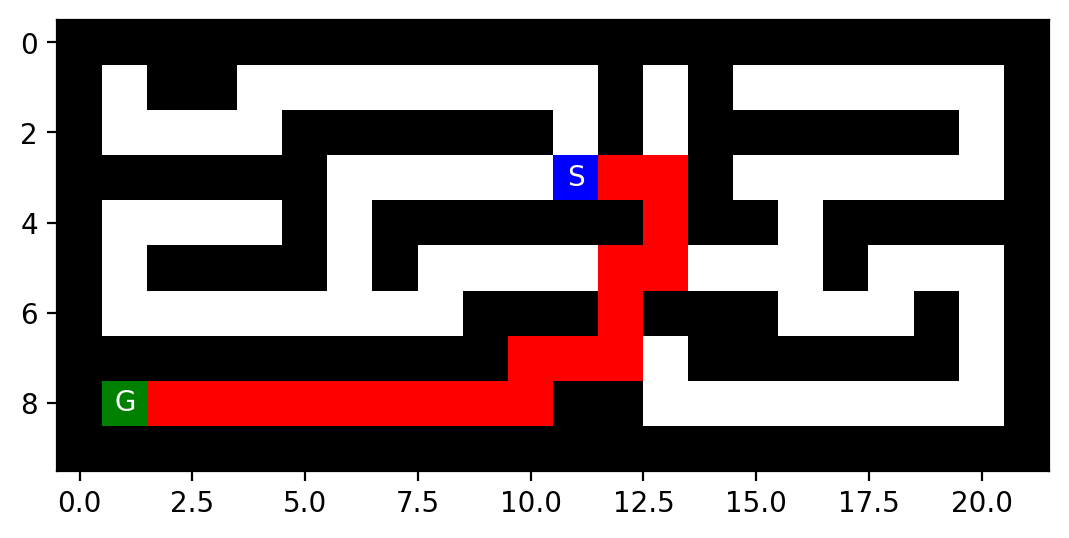

medium_maze.txt A*


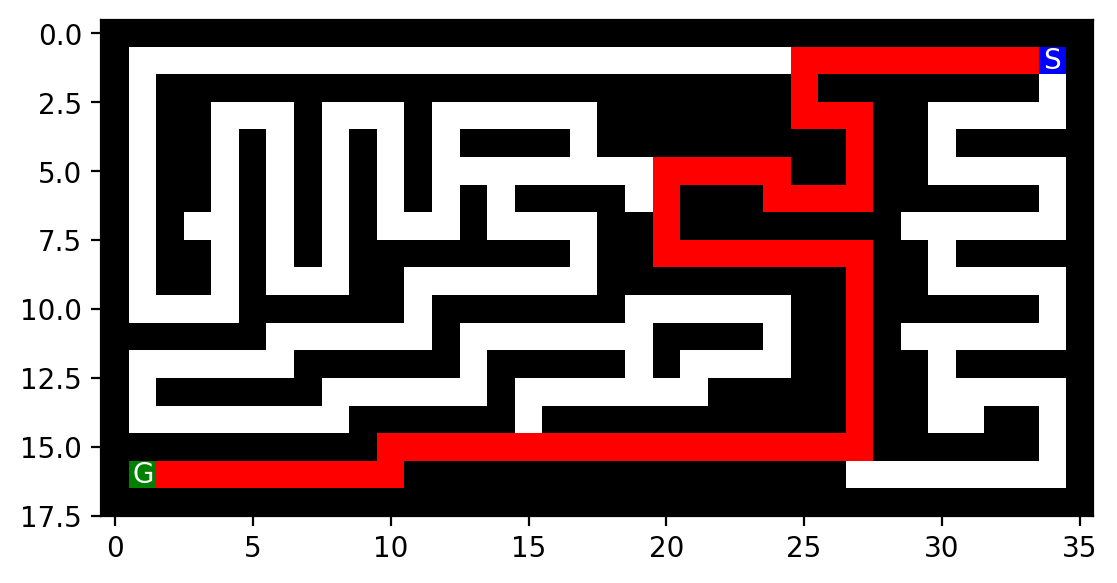

L_maze.txt GBFS


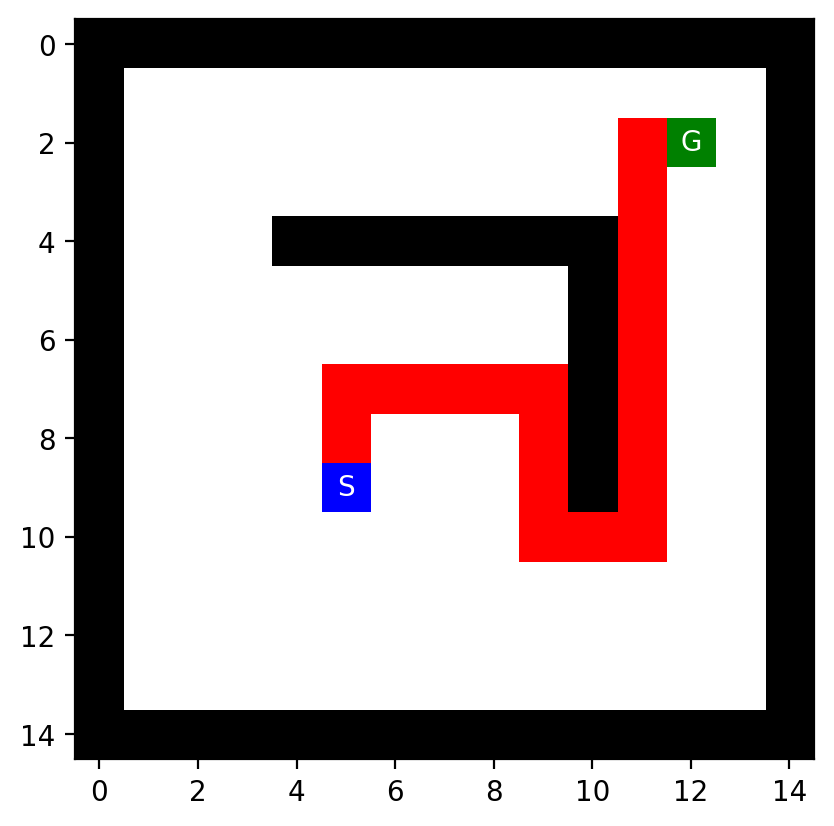

loops_maze.txt DFS


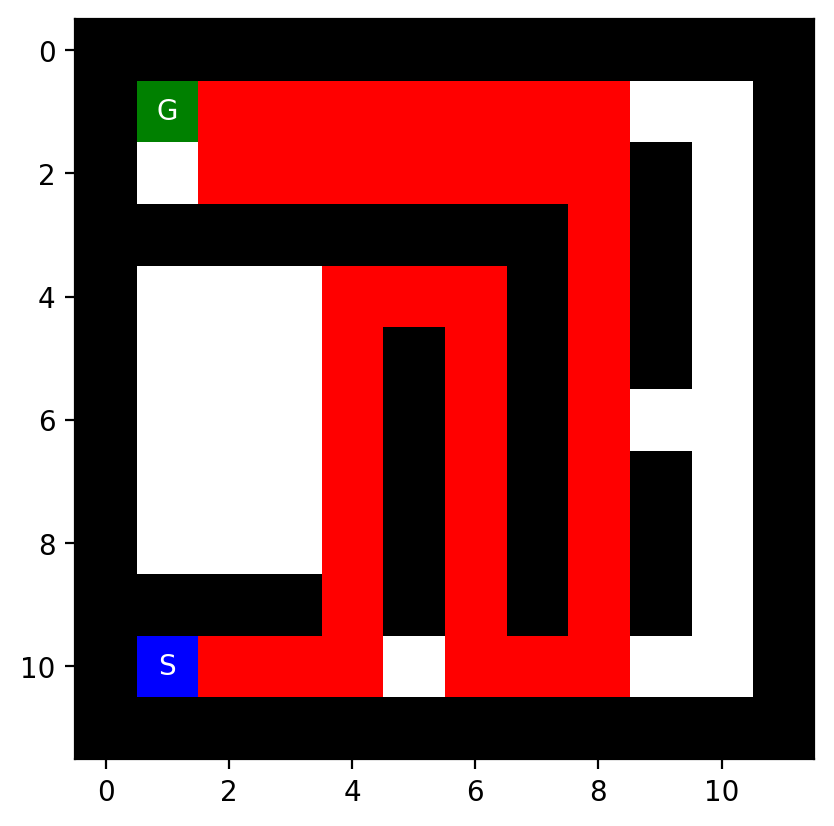

In [20]:
for fn,name in [('small_maze.txt','BFS'),('medium_maze.txt','A*'),('L_maze.txt','GBFS'),('loops_maze.txt','DFS')]:
    print(fn,name); mh.show_maze(mark_solution(load_maze(fn)[0],all_results[fn][name]))

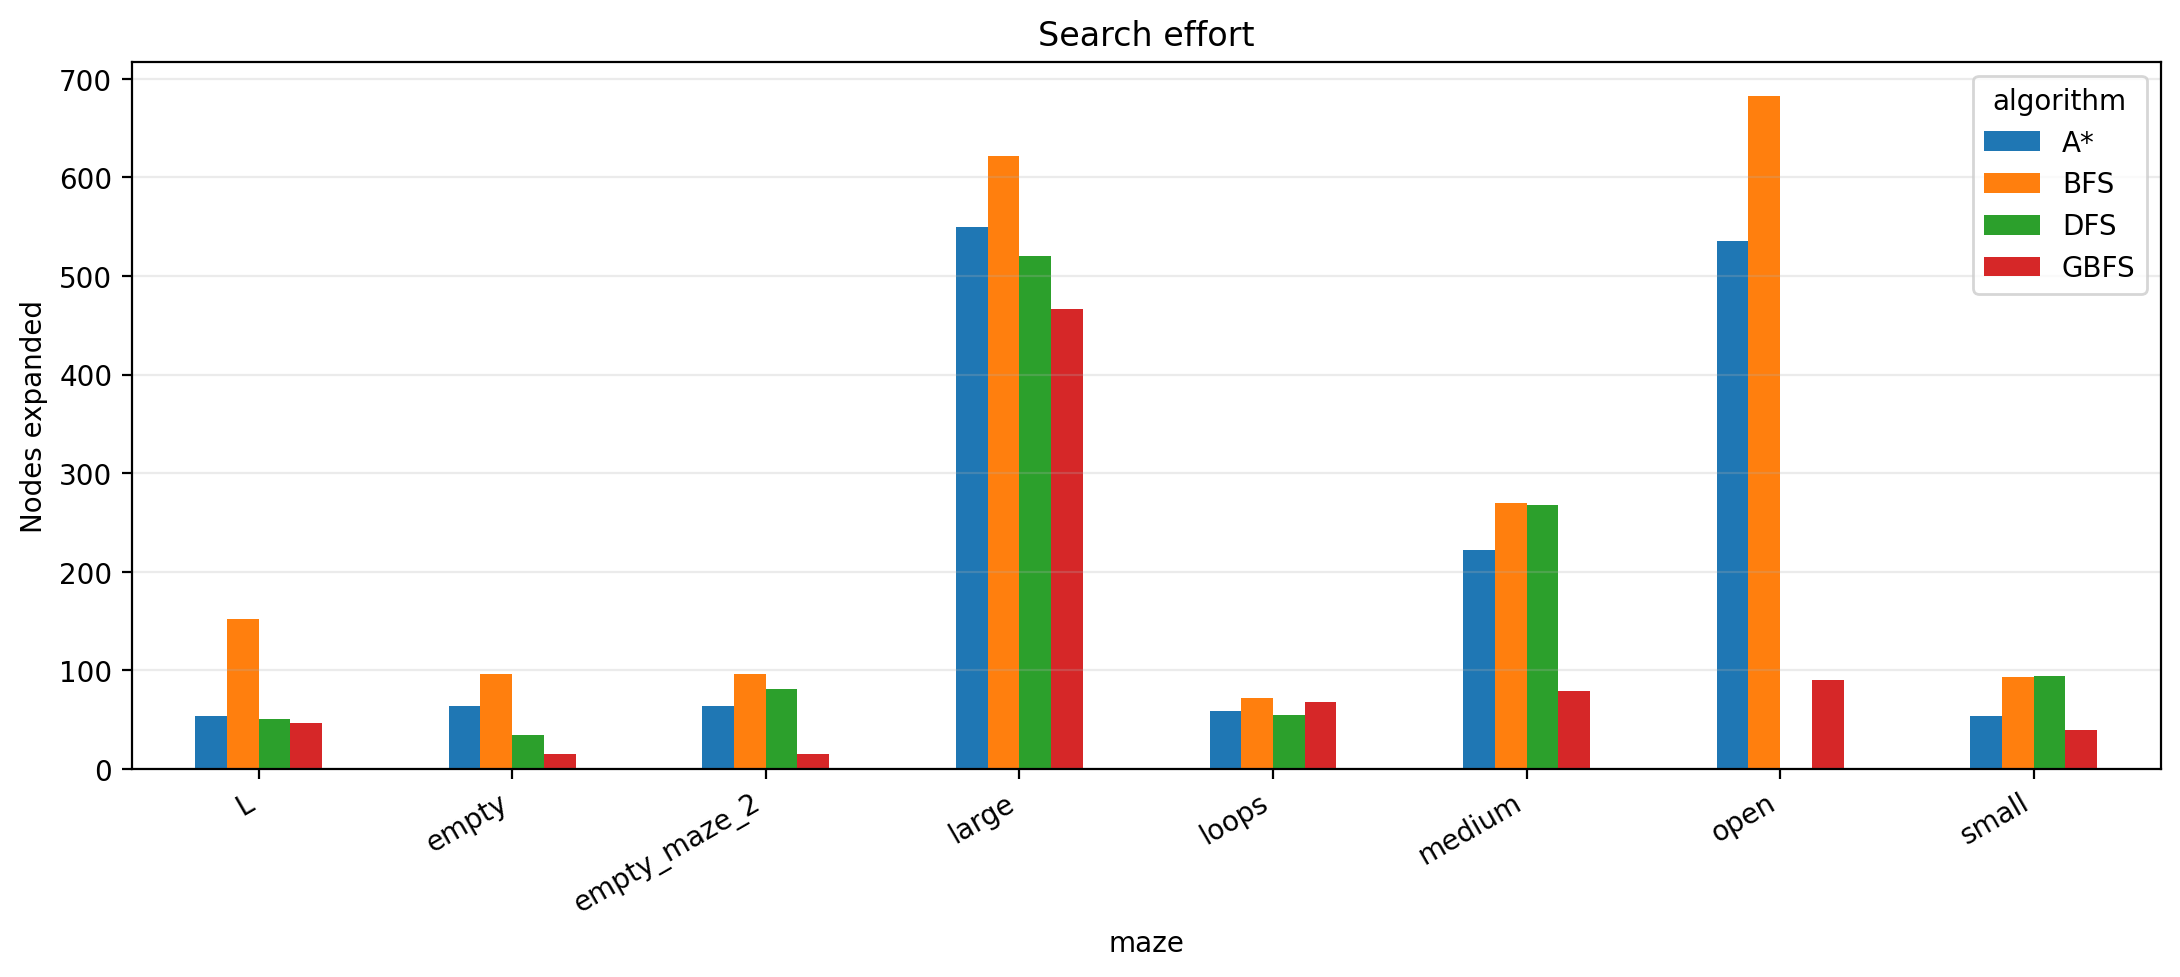

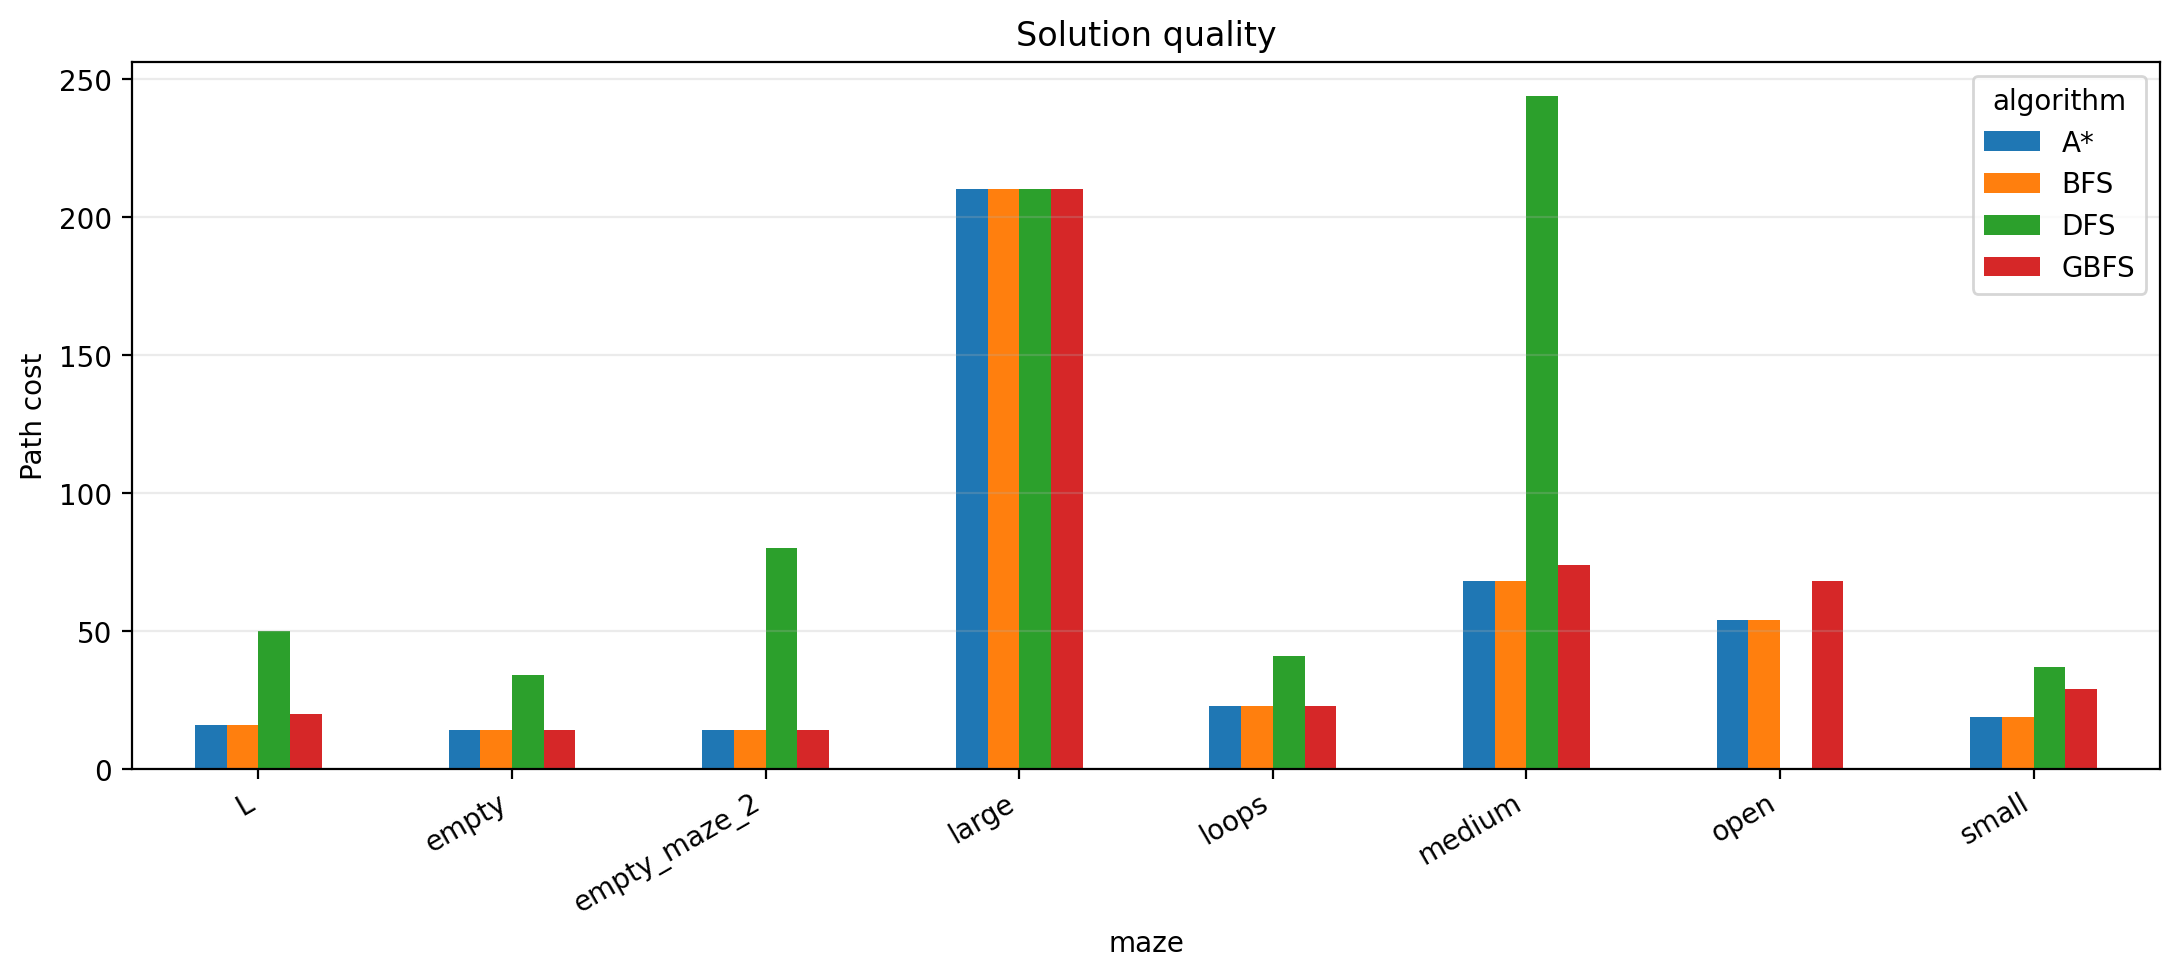

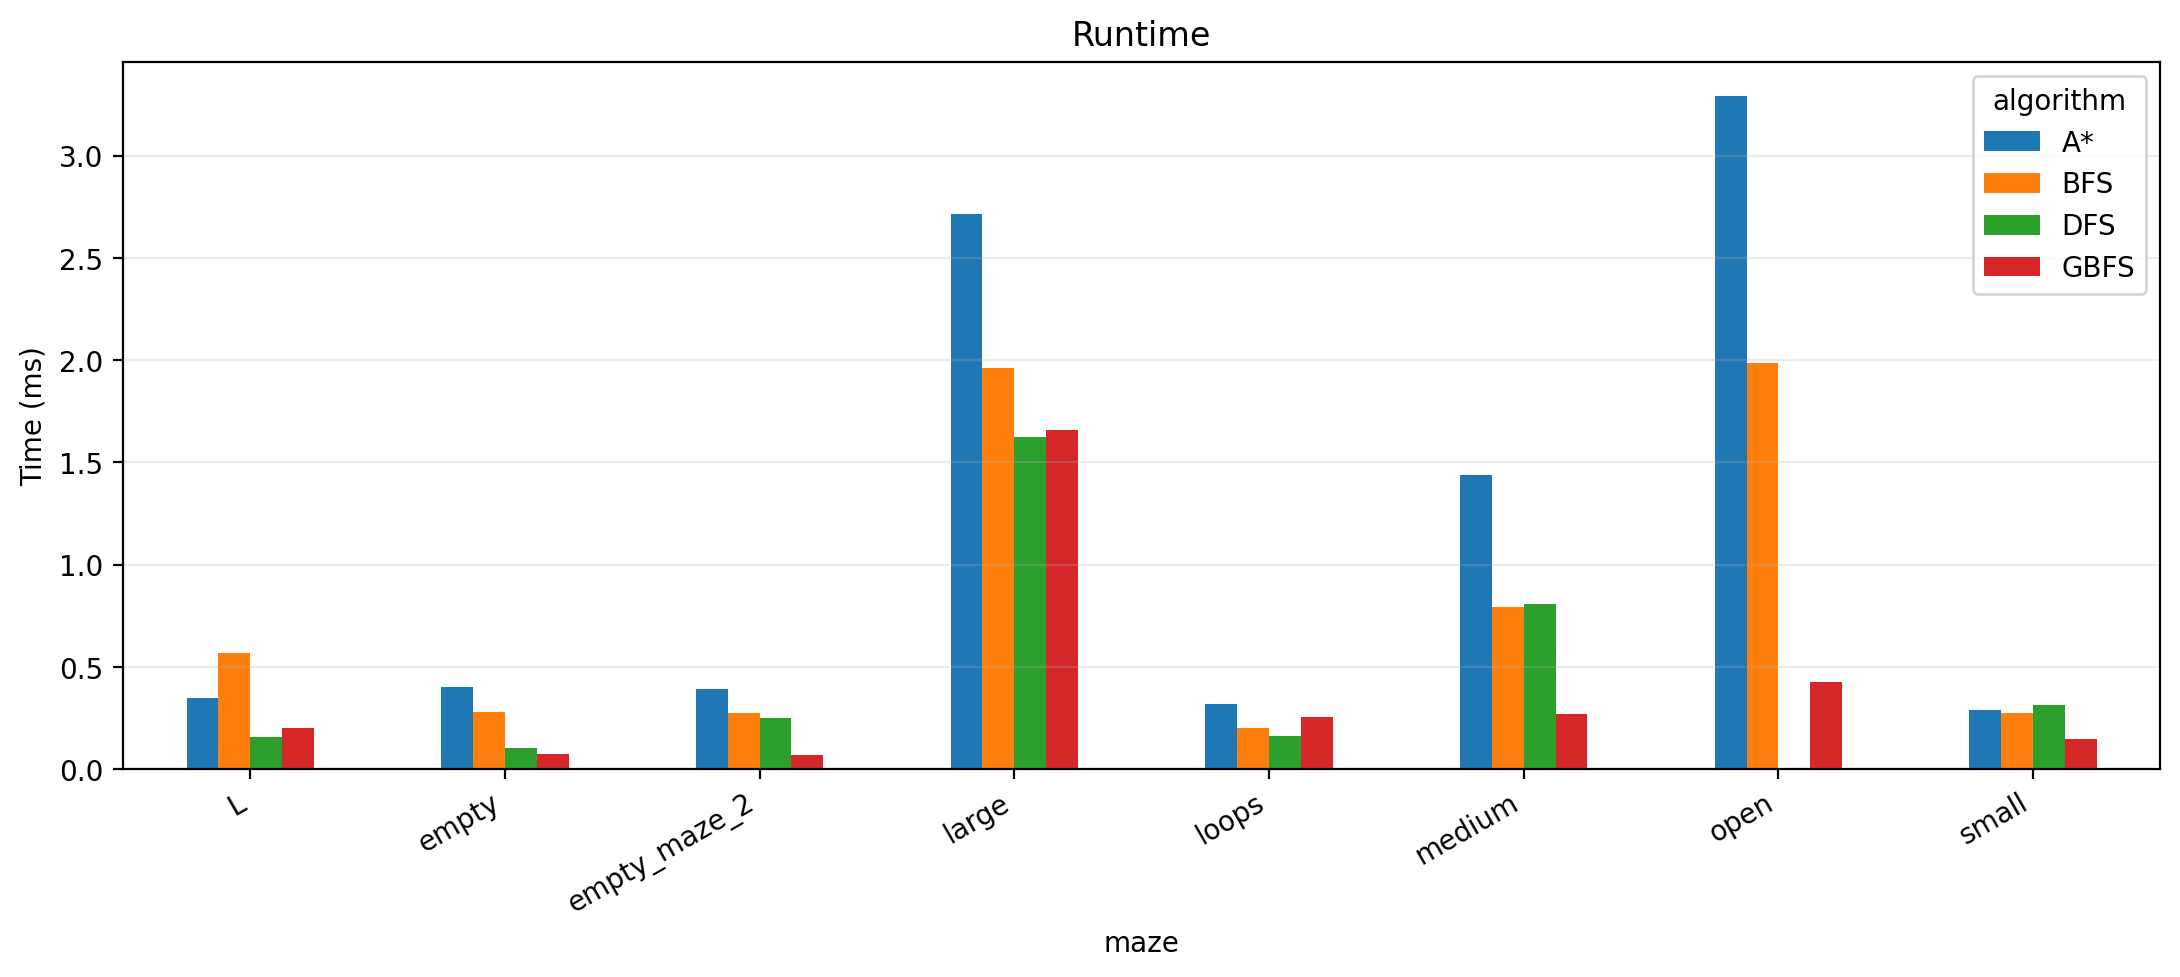

In [21]:
plot_df=results_df[results_df['path cost'].map(lambda x:isinstance(x,(int,float,np.integer,np.floating)))].copy()
for metric,ylabel,title in [
    ('nodes expanded','Nodes expanded','Search effort'),
    ('path cost','Path cost','Solution quality'),
    ('time (ms)','Time (ms)','Runtime')]:
    p=plot_df.pivot(index='maze',columns='algorithm',values=metric)
    ax=p.plot(kind='bar',figsize=(11,5))
    ax.set_ylabel(ylabel); ax.set_title(title); ax.grid(axis='y',alpha=.25)
    plt.xticks(rotation=30,ha='right'); plt.tight_layout(); plt.show()

Discuss the most important lessons you have learned from implementing the different search strategies. 

In [22]:
from IPython.display import Markdown,display
display(Markdown('''### Main lessons
- **BFS:** complete and optimal for unit-cost mazes, but memory grows quickly.
- **DFS:** lower active memory and not optimal; its path-only cycle checking can still cause huge repeated exploration.
- **GBFS:** often expands fewer states but can return a longer path because it uses only `h(n)`.
- **A*:** combines `g(n)` and `h(n)` and retains optimality with Manhattan on this grid.
- **Heuristics:** a better estimate focuses the search and reduces unnecessary expansion.
- **Cycle checking:** essential for DFS; the supplied open maze illustrates the practical difficulty of path-only checking.
'''))

### Main lessons
- **BFS:** complete and optimal for unit-cost mazes, but memory grows quickly.
- **DFS:** lower active memory and not optimal; its path-only cycle checking can still cause huge repeated exploration.
- **GBFS:** often expands fewer states but can return a longer path because it uses only `h(n)`.
- **A*:** combines `g(n)` and `h(n)` and retains optimality with Manhattan on this grid.
- **Heuristics:** a better estimate focuses the search and reduces unnecessary expansion.
- **Cycle checking:** essential for DFS; the supplied open maze illustrates the practical difficulty of path-only checking.


## Advanced task: IDS and Multiple goals

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### IDS 
Implement IDS (iterative deepening search) using your DFS implementation. Test IDS on the mazes above. You may run into some issues with mazes with open spaces. If you cannot resolve the issues, then report and discuss what causes the problems.

In [23]:
def depth_limited_search(maze,start,goal,limit,max_expansions=50_000):
    t=time.perf_counter(); root=Node(start); path={start}; stack=[[root,None,0]]
    expanded=depth=mf=0
    while stack:
        n,ch,i=stack[-1]
        if ch is None:
            expanded+=1; depth=max(depth,n.cost); mf=max(mf,len(stack))
            if expanded>max_expansions:
                return _result(None,expanded,depth,mf,mf,time.perf_counter()-t,'N/A* expansion limit',max_expansions)
            if n.pos==goal: return _result(n,expanded,depth,mf,mf,time.perf_counter()-t)
            ch=[] if n.cost>=limit else [Node(p,n,a,n.cost+1) for a,p in neighbors(maze,n.pos) if p not in path]
            stack[-1][1]=ch
        if i>=len(stack[-1][1]): path.remove(n.pos); stack.pop(); continue
        child=stack[-1][1][i]; stack[-1][2]+=1; path.add(child.pos); stack.append([child,None,0])
    return _result(None,expanded,depth,mf,mf,time.perf_counter()-t,'cutoff')

def ids(maze,start,goal,max_depth=None):
    max_depth=(int(np.count_nonzero(maze!='X'))-1 if max_depth is None else max_depth)
    total=md=mf=0
    for limit in range(max_depth+1):
        r=depth_limited_search(maze,start,goal,limit)
        total+=r['expanded']; md=max(md,r['max_depth']); mf=max(mf,r['max_frontier'])
        if r['path'] is not None or r['status'].startswith('N/A'):
            r['expanded']=total; r['max_depth']=md; r['max_frontier']=mf; return r
ids_rows=[]
for fn in MAZE_FILES:
    m,s,g=load_maze(fn); r=ids(m,s,g)
    ids_rows.append([fn.removesuffix('.txt').removesuffix('_maze'),r['cost'] if r['cost'] is not None else 'N/A*',r['expanded'],r['max_depth'],r['max_frontier'],r['status']])
ids_df=pd.DataFrame(ids_rows,columns=['maze','path cost','nodes expanded','max depth','max frontier','status'])
ids_df

,maze,path cost,nodes expanded,max depth,max frontier,status
0,small,19,1052,19,20,solved
1,medium,68,16243,68,69,solved
2,large,210,60966,210,211,solved
3,open,N/A*,90359,12,13,N/A* expansion limit
4,L,N/A*,121123,11,12,N/A* expansion limit
5,loops,23,99051,23,24,solved
6,empty,N/A*,131269,12,13,N/A* expansion limit
7,empty_maze_2,N/A*,131269,12,13,N/A* expansion limit


### Multiple Goals 
Create a few mazes with multiple goals by adding one or two more goals to the medium size maze. The agent is done when it finds one of the goals.
Solve the maze with your implementations for DFS, BFS, and IDS. Run experiments to show which implementations find the optimal solution and which do not. Discuss why that is the case.

In [24]:
# Multiple-goal experiment on medium maze: add two reachable goal cells.
medium,start,original=load_maze('medium_maze.txt')
multi=np.copy(medium); extra=[(1,14),(13,12)]
for p in extra: multi[p]='G'
goals={original,*extra}

def multi_search(kind):
    # BFS/DFS use the same frontier logic as above, but goal test is membership in goals.
    if kind=='BFS':
        root=Node(start); q=deque([root]); seen={start}; exp=0
        while q:
            n=q.popleft(); exp+=1
            if n.pos in goals:return n,exp
            for a,p in neighbors(multi,n.pos):
                if p not in seen:seen.add(p);q.append(Node(p,n,a,n.cost+1))
    root=Node(start); path={start}; stack=[[root,None,0]]; exp=0
    while stack:
        n,ch,i=stack[-1]
        if ch is None:
            exp+=1
            if n.pos in goals:return n,exp
            ch=[Node(p,n,a,n.cost+1) for a,p in neighbors(multi,n.pos) if p not in path]
            stack[-1][1]=ch
        if i>=len(stack[-1][1]):path.remove(n.pos);stack.pop();continue
        child=stack[-1][1][i];stack[-1][2]+=1;path.add(child.pos);stack.append([child,None,0])

rows=[]
for kind in ['BFS','DFS']:
    n,e=multi_search(kind); rows.append([kind,n.cost,e])
# IDS uses the same depth-limited idea; stop at the first goal.
def dls_multi(limit):
    root=Node(start); path={start}; stack=[[root,None,0]]; exp=0
    while stack:
        n,ch,i=stack[-1]
        if ch is None:
            exp+=1
            if n.pos in goals:return n,exp
            ch=[] if n.cost>=limit else [Node(p,n,a,n.cost+1) for a,p in neighbors(multi,n.pos) if p not in path]
            stack[-1][1]=ch
        if i>=len(stack[-1][1]):path.remove(n.pos);stack.pop();continue
        child=stack[-1][1][i];stack[-1][2]+=1;path.add(child.pos);stack.append([child,None,0])
    return None,exp
tot=0
for lim in range(int(np.count_nonzero(multi!='X'))):
    n,e=dls_multi(lim);tot+=e
    if n:break
rows.append(['IDS',n.cost,tot])
multi_df=pd.DataFrame(rows,columns=['algorithm','first goal path cost','nodes expanded'])
print('Goals:',sorted(goals)); multi_df

Goals: [(1, 14), (13, 12), (np.int64(16), np.int64(1))]


,algorithm,first goal path cost,nodes expanded
0,BFS,20,53
1,DFS,90,99
2,IDS,20,509


## More Advanced Problems to Think About (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Intersection as States
Instead of defining each square as a state, use only intersections as states. Now the storage requirement is reduced, but the path length between two intersections can be different. If we use total path length measured as the number of squares as path cost, how can we make sure that BFS and iterative deepening search is optimal? Change the code to do so.

In [25]:
# Optional intersection-as-states note (not required for credit).
# If edge costs between intersections differ, ordinary BFS/IDS by number of intersections
# is not enough to guarantee minimum total movement cost. Use uniform-cost search (or A*)
# with the true edge/path length as the cost; for IDS, use iterative deepening on cumulative
# path cost rather than number of edges (equivalent to an iterative-cost threshold search).

### Weighted A* search
Modify your A* search to add weights (see text book) and explore how different weights influence the result.

In [26]:
# Weighted A* — f_w(n)=g(n)+w*h(n). Increasing w makes the heuristic more influential.
maze,start,goal=load_maze('medium_maze.txt')
weighted=[]
for w in [1,1.5,2,5,10]:
    r=best_first(maze,start,goal,'A*',manhattan,w)
    weighted.append([w,r['cost'],r['expanded'],round(r['time']*1000,3)])
weighted_df=pd.DataFrame(weighted,columns=['w','path cost','nodes expanded','time (ms)'])
weighted_df

,w,path cost,nodes expanded,time (ms)
0,1.0,68,222,0.852
1,1.5,68,230,1.129
2,2.0,68,229,0.814
3,5.0,74,79,0.301
4,10.0,74,79,0.267


### Unknown Maze
What happens if the agent does not know the layout of the maze in advance? This means that the agent faces an unknown environment, where it does not know the transition function. How does the environment look then (PEAS description)? How would you implement a rational agent to solve the maze? What if the agent still has a GPS device to tell the distance to the goal?

In [27]:
from IPython.display import Markdown,display
display(Markdown('''### Unknown maze — PEAS and rational agent
**Performance:** reach the goal with low movement/exploration cost and avoid collisions.
**Environment:** finite grid maze with initially unknown walls/connectivity.
**Actuators:** move N/E/S/W.
**Sensors:** current position and local neighboring-cell observations; optional GPS gives position/distance information.

A rational agent maintains an internal map of discovered cells and explores safe frontier states.
After each observation it updates the map and replans. Once a route is known, BFS/A* can find a
shortest route on the discovered map. GPS distance can be used as an additional heuristic to
prioritize exploration, but it cannot reveal walls or the transition model by itself.'''))

### Unknown maze — PEAS and rational agent
**Performance:** reach the goal with low movement/exploration cost and avoid collisions.
**Environment:** finite grid maze with initially unknown walls/connectivity.
**Actuators:** move N/E/S/W.
**Sensors:** current position and local neighboring-cell observations; optional GPS gives position/distance information.

A rational agent maintains an internal map of discovered cells and explores safe frontier states.
After each observation it updates the map and replans. Once a route is known, BFS/A* can find a
shortest route on the discovered map. GPS distance can be used as an additional heuristic to
prioritize exploration, but it cannot reveal walls or the transition model by itself.